In [7]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [8]:
from tensorflow.keras.models import Sequential,Model
from tensorflow.keras.layers import Input, Dense, Flatten

In [9]:
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


In [10]:
# Keep only digit 0 images for training the autoencoder
x_train = x_train[y_train == 0]

# Normalize pixel values to the range 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Digit 0 training images:", x_train.shape)

Digit 0 training images: (5923, 28, 28)


In [11]:
# Flatten each 28x28 image into a 784-element vector
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Flattened training data:", x_train.shape)
print("Flattened testing data:", x_test.shape)

Flattened training data: (5923, 784)
Flattened testing data: (10000, 784)


In [13]:
input_layer = Input(shape=(784,))

# Encoder
encoded = Dense(16, activation='relu')(input_layer)
encoded = Dense(8, activation='relu')(encoded)
latent = Dense(4, activation='relu')(encoded)

# Decoder
decoded = Dense(8, activation='relu')(latent)
decoded = Dense(16, activation='relu')(decoded)
output_layer = Dense(784, activation='sigmoid')(decoded)

autoencoder = Model(input_layer, output_layer)

autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │        12,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 784)            │        13,328 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,244 (102.52 KB)

 Trainable params: 26,244 (102.52 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [16]:
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=32
)

Epoch 1/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0861 - mae: 0.1962
Epoch 2/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0519 - mae: 0.1235
Epoch 3/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0486 - mae: 0.1154
Epoch 4/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0478 - mae: 0.1139
Epoch 5/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0449 - mae: 0.1085
Epoch 6/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0393 - mae: 0.0966
Epoch 7/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0377 - mae: 0.0934
Epoch 8/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0362 - mae: 0.0907
Epoch 9/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0339 - mae: 0.0861
Epoch 10/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0322 - mae: 0.0823


In [18]:
prediction = autoencoder.predict(x_test)

# Mean squared reconstruction error for each test image
error = np.mean((x_test - prediction) ** 2, axis=1)

print('Number of reconstruction errors:', len(error))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Number of reconstruction errors: 10000


In [19]:
threshold = np.percentile(error, 95)
anomalies = error > threshold

print("Threshold:", threshold)
print("Anomaly:", sum(anomalies))
print("Normal Records:", sum(~anomalies))

Threshold: 0.10012465443279911
Anomaly: 500
Normal Records: 9500


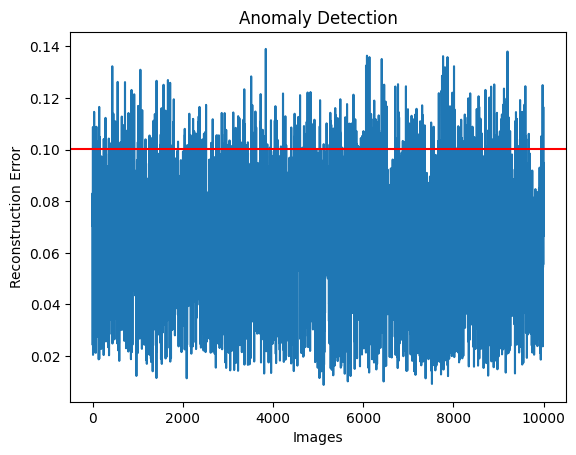

In [20]:
plt.plot(error)
plt.axhline(threshold, color='red')
plt.title('Anomaly Detection')
plt.xlabel('Images')
plt.ylabel('Reconstruction Error')
plt.show()